In [27]:
import matplotlib.pyplot as plt
import nelpy as nel
import nelpy.plotting as npl
import numpy as np
import seaborn as sns
from neuro_py.io import loading
from neuro_py.plotting.figure_helpers import set_size
from neuro_py.tuning import maps
from skimage import measure
import os
import pandas as pd
import scipy.io as sio
import logging

logging.getLogger().setLevel(logging.ERROR)
basepath =  r"W:\data\PPP\PPP23\day8"
basename=os.path.basename(basepath)# Define the new folder path
#create working folder
new_folder_path = os.path.join(basepath, "complex_system")
brain_region="CA1"
animal="mouse"   #or Mouse
cell_type='all'
path_parts = basepath.split("\\")  # Split the path using backslash
animal_name = path_parts[-2]  # Second-to-last part is the animal name
day = path_parts[-1]  # Last part is the day
save_dir = r"D:\Documents\GitHub\R_Project\PPP\codebook\Criticality_analysis\complex_system\manifold"
if not os.path.exists(save_dir):
    os.makedirs(save_dir)
# Create the folder if it doesn't exist
if not os.path.exists(new_folder_path):
    os.makedirs(new_folder_path)
    print(f"Folder created: {new_folder_path}")
else:
    print(f"Folder already exists: {new_folder_path}")
# load in spike data from hpc pyramidal cells
st, cm = loading.load_spikes(
    basepath, brainRegion=brain_region                          # putativeCellType="Pyr"
)
# load theta epochs
state_dict = loading.load_SleepState_states(basepath)
nrem_epochs = nel.EpochArray(
    state_dict["NREMstate"],
)
awake_epochs = nel.EpochArray(
    state_dict["WAKEstate"],
)
# theta_epochs = nel.EpochArray(
#     state_dict["THETA"],
# )
rem_epochs=nel.EpochArray(state_dict["REMstate"],)
try:
    # Try default loader
    epoch_df = loading.load_epoch(basepath)
except Exception as e:
    print(f"load_epoch failed with error: {e}")
    print("Falling back to manual .mat file load...")

    # Load the .mat file
    mat = sio.loadmat(os.path.join(basepath, "DayNight25.MergePoints.events.mat"), squeeze_me=True)

    # Extract the 'MergePoints' structure
    merge_points = mat['MergePoints']

    # Extract the timestamps array: shape (N, 2)
    timestamps = merge_points['timestamps']  # this is the field you're interested in
    # Unwrap the array inside
    timestamps = np.array(timestamps.tolist())

    # Now you should have shape (N, 2)
    epoch_df = pd.DataFrame(timestamps, columns=["startTime", "stopTime"])

sleep_epochs = nel.EpochArray(np.array([epoch_df.startTime, epoch_df.stopTime]).T)
E_spikes = st.time[(cm.putativeCellType == 'Pyramidal Cell')]
I_spikes= st.time[(cm.putativeCellType.str.contains("Interneuron"))]
spike_times=st.time
n_cell=len(spike_times)
print(f"number of cells: {n_cell}")

Folder already exists: W:\data\PPP\PPP23\day8\complex_system
number of cells: 254


In [28]:
import numpy as np
import scipy.io as sio      
import scipy
# Load ripple events
ripple_events = loading.load_ripples_events(basepath=basepath)
ripple_epochs = nel.EpochArray(np.array([ripple_events.start, ripple_events.stop]).T)
ripple_peaks=ripple_events.peaks
    # Load barrage events
ripple_epochs=nrem_epochs&ripple_epochs
try:
    # Load barrage events
    #brpath=r"W:\data\PPP\CA2\PPP7\day8"
    barrage_events = loading.load_barrage_events(basepath=basepath)  
    # Create barrage epochs
    barrage_epochs = nel.EpochArray(np.array([barrage_events.start, barrage_events.stop]).T)
    # Find barrages in NREM epochs
    barrages_in_nrem = barrage_epochs & nrem_epochs
    mat_path = os.path.join(basepath, f'{basename}.HSEn2.events.mat')

    data = scipy.io.loadmat(mat_path, struct_as_record=False, squeeze_me=True)
    barrage = data['HSEn2']
    barrage_timestamps= barrage.timestamps 
    barrage_epochs=nrem_epochs&barrage_epochs
except Exception as e:
    # General exception for unexpected errors
    print(f"No barrage file: {e}")
    barrage_epochs=[]
    # Extract start times

No barrage file: 'DataFrame' object has no attribute 'start'


D:\Documents\GitHub\neuro_py\neuro_py\io\loading.py:1036: UserWarning: No barrage file found for W:\data\PPP\PPP23\day8


In [29]:
import os, re, numpy as np, pandas as pd
import glob  # <-- add this
def _load_mat_any(mat_path):
    from scipy.io import loadmat
    try:
        return loadmat(
            mat_path,
            squeeze_me=True,
            struct_as_record=False,
            simplify_cells=True
        )
    except TypeError:
        return loadmat(
            mat_path,
            squeeze_me=True,
            struct_as_record=False
        )
    except NotImplementedError:
        import mat73
        return mat73.loadmat(mat_path)
def _to_1d_array(x):
    """
    Robustly coerce MATLAB-loaded field to a 1D numpy array.
    - Scalars -> 1-length array
    - Lists/tuples/ndarrays -> flattened 1D
    - None / missing -> empty array
    """
    if x is None:
        return np.array([], dtype=float)
    arr = np.asarray(x, dtype=object)  # start as object to avoid surprises
    if arr.ndim == 0:
        # scalar or unsized object
        return np.atleast_1d(arr).astype(float, copy=False)
    # flatten and try float cast (ignore non-numeric gracefully)
    try:
        return np.asarray(arr).ravel().astype(float, copy=False)
    except (ValueError, TypeError):
        # fallback: best-effort, convert elementwise
        return np.array([float(v) for v in np.ravel(arr)], dtype=float)

def _to_state_str(s):
    # MATLAB char arrays sometimes come in as numpy arrays
    try:
        if isinstance(s, (bytes, bytearray)):
            return s.decode('utf-8', 'ignore')
        if isinstance(s, str):
            return s
        # arrays or weird containers -> join characters
        arr = np.asarray(s)
        if arr.ndim == 0:
            return str(arr.item())
        # e.g., array of characters
        return ''.join(arr.tolist()) if arr.dtype.kind in ('U','S') else str(arr)
    except Exception:
        return str(s)

def load_d2_timeline_complete(basepath, region):
    """Complete version that loads ALL sleep-state data, including d2_err."""
    region = region.upper()
    search_dir = os.path.join(basepath, "complex_system")
    pats = [f"*_{region}_D2_time_resolved_rippleablate.mat", f"*_{region}_D2_time_rippleablate.mat"]
    #pats = [f"*_{region}_D2_time_resolved_error_bar.mat", f"*_{region}_D2_time_error_bar.mat"]
    files = []
    for pat in pats:
        files.extend(glob.glob(os.path.join(search_dir, pat)))
    if not files:
        raise FileNotFoundError(f"No *_{region}_D2_time*.mat under {search_dir}")

    mat_path = max(files, key=os.path.getmtime)
    print(f"Loading: {os.path.basename(mat_path)}")

    mat = _load_mat_any(mat_path)
    results = mat['results']
    params = mat.get('params', {})

    # Make results iterable no matter if it's a list, ndarray, or dict
    if isinstance(results, dict):
        iter_results = list(results.values())
    else:
        iter_results = list(results if isinstance(results, (list, tuple)) else np.atleast_1d(results))

    print(f"📊 Found {len(iter_results)} result items (sleep states)")
    print(f"📊 Parameters: {params}")

    # Try to infer animal/day from filename if available
    fname = os.path.basename(mat_path)
    animal_name = None
    day = None
    m_day = re.search(r'day(\d+)', fname, flags=re.I)
    if m_day:
        day = int(m_day.group(1))
    m_animal = re.match(r'([^_]+)_day\d+_', fname)
    if m_animal:
        animal_name = m_animal.group(1)

    all_centers, all_d2, all_d2err, all_states = [], [], [], []
    n_states_with_err = 0

    for i, result_item in enumerate(iter_results):
        # Access as dict-like regardless of MATLAB struct quirks
        state = _to_state_str(result_item.get('state', 'UNKNOWN')) if hasattr(result_item, 'get') else \
                _to_state_str(result_item['state']) if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) else 'UNKNOWN'

        centers_raw = result_item.get('center', []) if hasattr(result_item, 'get') else \
                      (result_item['center'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'center' in result_item else [])
        d2_raw = result_item.get('d2', []) if hasattr(result_item, 'get') else \
                 (result_item['d2'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2' in result_item else [])
        d2err_raw = result_item.get('d2_err', []) if hasattr(result_item, 'get') else \
                    (result_item['d2_err'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2_err' in result_item else [])

        centers  = _to_1d_array(centers_raw)
        d2_vals  = _to_1d_array(d2_raw)
        d2_err   = _to_1d_array(d2err_raw)

        # Presence flag (some states may not have d2_err)
        has_err = d2_err.size > 0 and np.any(np.isfinite(d2_err))
        n_states_with_err += int(has_err)

        # Harmonize lengths: truncate all to the common min
        sizes = [centers.size, d2_vals.size] + ([d2_err.size] if has_err else [])
        n_pts = min(sizes) if min(sizes) > 0 else 0
        print(f"   State {i}: {state} - requested points={centers.size}, actual used={n_pts}")

        if n_pts == 0:
            print("     ⚠️ Empty state - no data points")
            continue

        centers = centers[:n_pts]
        d2_vals = d2_vals[:n_pts]
        d2_err  = (d2_err[:n_pts] if has_err else np.full(n_pts, np.nan, dtype=float))

        # Ranges
        try:
            print(f"     Time range: {float(np.nanmin(centers))} to {float(np.nanmax(centers))}")
        except ValueError:
            print("     Time range: (all NaN)")

        try:
            print(f"     D2 range: {float(np.nanmin(d2_vals)):.4f} to {float(np.nanmax(d2_vals)):.4f}")
        except ValueError:
            print("     D2 range: (all NaN)")

        if np.any(np.isfinite(d2_err)):
            try:
                dmin, dmax = float(np.nanmin(d2_err)), float(np.nanmax(d2_err))
                print(f"     D2_ERR range: {dmin:.4f} to {dmax:.4f}")
            except ValueError:
                print("     D2_ERR range: (all NaN)")
        else:
            print("     D2_ERR: missing → filled with NaN")

        all_centers.append(centers)
        all_d2.append(d2_vals)
        all_d2err.append(d2_err)
        all_states.append(np.array([state]*n_pts, dtype=object))

    if len(all_centers) == 0:
        raise ValueError("No data found in any sleep state - all states are empty")

    # Concatenate
    all_centers = np.concatenate(all_centers)
    all_d2      = np.concatenate(all_d2)
    all_d2err   = np.concatenate(all_d2err)
    all_states  = np.concatenate(all_states)

    # DataFrame (include d2_err)
    df = pd.DataFrame({
        'center_s': all_centers.astype(float, copy=False),
        'd2':       all_d2.astype(float, copy=False),
        'd2_err':   all_d2err.astype(float, copy=False),
        'state':    all_states.astype(str)
    }).sort_values('center_s').reset_index(drop=True)

    print(f"\n✅ Complete timeline created:")
    print(f"📊 Total data points: {len(df)}")
    print(f"📊 Time range: {df['center_s'].min()} to {df['center_s'].max()}")
    print(f"📊 Duration: {(df['center_s'].max() - df['center_s'].min()):.1f} seconds")
    print(f"📊 State distribution:")
    print(df['state'].value_counts())

    # Empty-state tracker
    empty_states = []
    for ri in iter_results:
        st = _to_state_str(ri.get('state','UNKNOWN')) if hasattr(ri,'get') else \
             _to_state_str(ri['state']) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'state' in ri else 'UNKNOWN'
        csz = np.size(np.atleast_1d(ri.get('center', []))) if hasattr(ri,'get') else \
              np.size(np.atleast_1d(ri['center'])) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'center' in ri else 0
        if csz == 0:
            empty_states.append(st)

    meta = {
        "animal_name": animal_name,
        "day": day,
        "region": region,
        "path": mat_path,
        "params": params,
        "columns": list(df.columns),
        "shape": df.shape,
        "n_states": len(iter_results),
        "states_with_d2_err": n_states_with_err,
        "empty_states": empty_states
    }

    return df, meta



# Test the complete loading function
try:
    ca1_complete_df, ca1_complete_meta = load_d2_timeline_complete(basepath, "CA1")
    
    # pfc_complete_df, pfc_complete_meta = load_d2_timeline_complete(basepath, "PFC")

    
except Exception as e:
    print(f"❌ Failed: {e}")
    import traceback
    traceback.print_exc()

print("\n" + "="*60)

Loading: day8_CA1_D2_time_resolved_rippleablate.mat
📊 Found 3 result items (sleep states)
📊 Parameters: {'window_size': 30, 'step_size': 2, 'guard_sec': 5, 'deltaT': 0.04, 'order': 20, 'quant': 0.1, 'brain_region': 'CA1', 'n_cells': 254, 'total_spikes': 17864193}
   State 0: NREM - requested points=3685, actual used=3685
     Time range: 1270.0 to 25717.0
     D2 range: 0.0212 to 0.1673
     D2_ERR range: 0.9933 to 0.9987
   State 1: REM - requested points=23, actual used=23
     Time range: 11879.0 to 24605.0
     D2 range: 0.0260 to 0.0831
     D2_ERR range: 0.9933 to 0.9960
   State 2: WAKE - requested points=7390, actual used=7390
     Time range: 21.0 to 24868.0
     D2 range: 0.0089 to 0.2084
     D2_ERR range: 0.9932 to 0.9995

✅ Complete timeline created:
📊 Total data points: 11098
📊 Time range: 21.0 to 25717.0
📊 Duration: 25696.0 seconds
📊 State distribution:
state
WAKE    7390
NREM    3685
REM       23
Name: count, dtype: int64



In [30]:
epoch_df

,name,startTime,stopTime,environment,behavioralParadigm,manipulation,stimuli,notes,basepath
0,presleep_240420_091750,0.0000,5749.17115,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
1,T_maze2_240420_111559,5749.1712,7603.38555,task,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
2,midsleep_240420_115822,7603.3856,14809.19675,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
3,T_maze1_240420_142305,14809.1968,16836.44795,task,1,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
4,postsleep_240420_145859,16836.4480,25738.00315,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8


In [31]:
sleep_epochs

<EpochArray at 0x2be29fbd510: 5 epochs> of length 7:08:58:003 hours

In [32]:
ca1_complete_df

,center_s,d2,d2_err,state
0,21.0,0.104689,0.997514,WAKE
1,23.0,0.106731,0.997463,WAKE
2,25.0,0.110388,0.997451,WAKE
3,27.0,0.107176,0.997332,WAKE
4,29.0,0.115440,0.997393,WAKE
...,...,...,...,...
11093,25709.0,0.085679,0.997258,NREM
11094,25711.0,0.092983,0.997326,NREM
11095,25713.0,0.088326,0.997249,NREM
11096,25715.0,0.085667,0.997251,NREM


In [33]:
ca1_complete_df

,center_s,d2,d2_err,state
0,21.0,0.104689,0.997514,WAKE
1,23.0,0.106731,0.997463,WAKE
2,25.0,0.110388,0.997451,WAKE
3,27.0,0.107176,0.997332,WAKE
4,29.0,0.115440,0.997393,WAKE
...,...,...,...,...
11093,25709.0,0.085679,0.997258,NREM
11094,25711.0,0.092983,0.997326,NREM
11095,25713.0,0.088326,0.997249,NREM
11096,25715.0,0.085667,0.997251,NREM


SWR and barrage

In [34]:
epoch_df

,name,startTime,stopTime,environment,behavioralParadigm,manipulation,stimuli,notes,basepath
0,presleep_240420_091750,0.0000,5749.17115,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
1,T_maze2_240420_111559,5749.1712,7603.38555,task,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
2,midsleep_240420_115822,7603.3856,14809.19675,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
3,T_maze1_240420_142305,14809.1968,16836.44795,task,1,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
4,postsleep_240420_145859,16836.4480,25738.00315,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8


In [35]:
import scipy.io
import numpy as np
from scipy.ndimage import zoom
from scipy.interpolate import interp1d
import umap
import matplotlib.pyplot as plt

## Load data
mat_path = f'D:/Documents/GitHub/R_Project/PPP/codebook/Criticality_analysis/replay_results/{animal_name}_{day}_replay_sequences_new.mat'
data = scipy.io.loadmat(mat_path)

# Define epochs and templates
epochs = ['epoch5']  # only use epoch1,3,4
template = 'template04'  # only use template02
bin_size = 0.01  # 10 ms
target_bins = 30  # fixed number of bins for all events

# Assume these are already loaded:
# E_spikes: list of spike times (one per unit)
# E_CellID: list of unit IDs corresponding to E_spikes

binned_firing_rates = []
avg_pos = []
epoch_labels = []
left_replay = []
right_replay = []
left_replay = []
left_times  = []

right_replay = []
right_times  = []
left_intervals=[]
right_intervals=[]
left_replay_goodfit=[]
right_replay_goodfit=[]
left_replay_slope=[]
right_replay_slope=[]
left_all_bestseq = []
right_all_bestseq = []
left_replay_matrix=[]
right_replay_matrix=[]
all_intervals=[]
for e in epochs:
    key_event = f'{e}_{template}_eventtimes'
    key_seq   = f'{e}_{template}'
    key_pval  = f'{e}_{template}_pvalue'
    key_Goodfit  = f'{e}_{template}_Goodfit'
    key_pval_r= f'{e}_{template}_rvalues'
    key_slope  = f'{e}_{template}_slope'
    key_best_seq  = f'{e}_{template}_all_best_seq'
    if key_event not in data or key_seq not in data:
        continue

    events = data[key_event].squeeze()
    seqs   = data[key_seq][0]
    pvals  = data[key_pval].squeeze()
    pvals_r= data[key_pval_r].squeeze()
    Goodfit  = data[key_Goodfit].squeeze()
    slope  = data[key_slope].squeeze()
    best_seq   = data[key_best_seq].squeeze()
    if events.ndim == 1:
        events = np.expand_dims(events, axis=0)

    for i, event in enumerate(events):
        if i >= len(seqs):
            continue

        pval = np.squeeze(pvals[i])   # [left_pval, right_pval]
        s = np.squeeze(seqs[i])       # decoded sequence, shape (T,)
        all_bestseq = np.squeeze(best_seq[i])       # decoded sequence, shape (T,)

        s_half = s.shape[1] // 2
        event_time = np.mean(event)  # use midpoint time

        # Left significant
        if pval[0] < 0.05 and pvals_r[i][0] < 0.05:
            left_replay.append(np.argmax(s[:,:s_half], axis=0) )
            left_times.append(event_time)
            left_intervals.append(event)
            left_replay_goodfit.append(Goodfit[i,0])
            left_replay_slope.append(slope[i][0, 0])
            left_all_bestseq.append(all_bestseq[:s_half])
            left_replay_matrix.append(s[:, :s_half])
        # Right significant
        if pval[1] < 0.05 and pvals_r[i][1] <0.05:
            right_replay.append(np.argmax(s[:,s_half:], axis=0))
            right_times.append(event_time)
            right_intervals.append(event)
            right_replay_goodfit.append(Goodfit[i,1])
            right_replay_slope.append(slope[i][0, 1])
            right_all_bestseq.append(all_bestseq[s_half:])
            right_replay_matrix.append(s[:, s_half:]) 
        if (pval[0] < 0.05 and pvals_r[i][0] < 0.05) or (pval[1] < 0.05 and pvals_r[i][1] <0.05):
            all_intervals.append(event)
 

replay ripple non-replay ripple

In [36]:
combined_intervals = np.array(all_intervals)
# take the last epoch
epoch_sel = epoch_df.iloc[[-1]]   # index = -1, keep as DataFrame

mask = (
    (ca1_complete_df["center_s"] >= epoch_sel.iloc[0]["startTime"]) &
    (ca1_complete_df["center_s"] <= epoch_sel.iloc[0]["stopTime"])
)

ca1_sel = ca1_complete_df.loc[mask].copy()
epoch_idx = epoch_df.index[epoch_df["name"].isin(epochs)].to_list()
print("Selected epoch indices:", epoch_idx)
import re
import numpy as np

# -------------------------
# inputs
# -------------------------

# -------------------------
# parse "epochK" -> integer K
# -------------------------
def parse_epoch_label_to_int(s):
    m = re.fullmatch(r"epoch(\d+)", str(s).strip(), flags=re.IGNORECASE)
    if not m:
        raise ValueError(f"Bad epoch label: {s} (expected like 'epoch3')")
    return int(m.group(1))

k_list = [parse_epoch_label_to_int(s) for s in epochs]  # [1,3,5]

# -------------------------
# choose indexing convention:
# If you truly want epoch1 -> row 1 (SECOND row), keep ONE_BASED=True.
# If you want epoch1 -> row 0 (FIRST row), set ONE_BASED=False.
# -------------------------
ONE_BASED = False

if ONE_BASED:
    iloc_idx = [k for k in k_list]          # epoch1 -> iloc[1]
else:
    iloc_idx = [k-1 for k in k_list]        # epoch1 -> iloc[0]

# bounds check
n_epochs = len(epoch_df)
bad = [i for i in iloc_idx if i < 0 or i >= n_epochs]
if bad:
    raise IndexError(f"Epoch indices out of range for epoch_df (n={n_epochs}): {bad}")

# -------------------------
# select those epochs from epoch_df
# -------------------------
epoch_sel = epoch_df.iloc[iloc_idx].copy()

print("Selected epoch rows (iloc):", iloc_idx)
print(epoch_sel[["name", "startTime", "stopTime"]])

# -------------------------
# filter ca1_complete_df by containment in ANY selected epoch interval
# -------------------------
mask = np.zeros(len(ca1_complete_df), dtype=bool)
cent = ca1_complete_df["center_s"].to_numpy(float)

for _, r in epoch_sel.iterrows():
    s0 = float(r["startTime"])
    s1 = float(r["stopTime"])
    mask |= (cent >= s0) & (cent <= s1)

ca1_complete_df = ca1_complete_df.loc[mask].copy()

print("Original rows:", len(ca1_complete_df))

Selected epoch indices: []
Selected epoch rows (iloc): [4]
                      name  startTime     stopTime
4  postsleep_240420_145859  16836.448  25738.00315
Original rows: 3857


In [37]:
# === GLM Analysis: MUA vs d2 predicting replay probability ===
import numpy as np
import pandas as pd
from sklearn.linear_model import PoissonRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss
import matplotlib.pyplot as plt
import seaborn as sns

print("="*60)
print("GLM ANALYSIS: MUA vs D2 predicting replay probability")
print("="*60)

# Parameters
window_size = 30 # seconds

# Get ripple epochs as array
ripples = ripple_epochs.data
print(f"\nTotal ripples in NREM: {len(ripples)}")
print(f"Total replay intervals: {len(combined_intervals)}")

# --- Step 1: Calculate replay probability for each ripple ---
print(f"\nStep 1: Calculating replay probability for each ripple...")

def overlaps_any(interval, others):
    """Check if interval overlaps with any interval in others"""
    a0, a1 = interval
    if others.size == 0:
        return False
    return np.any((a0 < others[:,1]) & (a1 > others[:,0]))

# Mark which ripples contain replay
ripple_has_replay = np.fromiter(
    (overlaps_any(r, combined_intervals) for r in ripples),
    dtype=bool, count=len(ripples)
)

print(f"Ripples with replay: {ripple_has_replay.sum()} ({100*ripple_has_replay.mean():.1f}%)")
print(f"Ripples without replay: {(~ripple_has_replay).sum()} ({100*(~ripple_has_replay).mean():.1f}%)")

# --- Step 2: For each center_s, calculate replay probability in window ---
print(f"\nStep 2: Calculating replay probability in {window_size}s windows...")

def count_ripples_in_window(ripples_array, center, window, has_replay_mask=None):
    """Count ripples (optionally filtered) in window around center"""
    w0, w1 = center - window/2, center + window/2
    in_window = (ripples_array[:,0] < w1) & (ripples_array[:,1] > w0)
    
    if has_replay_mask is not None:
        # Count only ripples with replay
        return (in_window & has_replay_mask).sum()
    else:
        # Count all ripples
        return in_window.sum()

# Calculate for each ca1_complete_df row
replay_probs = []
ripple_counts = []
replay_counts = []

for center in ca1_complete_df['center_s'].values:
    n_ripples = count_ripples_in_window(ripples, center, window_size)
    n_replay = count_ripples_in_window(ripples, center, window_size, ripple_has_replay)
    
    ripple_counts.append(n_ripples)
    replay_counts.append(n_replay)
    
    # Replay probability = n_replay / n_ripples (avoid division by zero)
    if n_ripples > 0:
        replay_probs.append(n_replay / n_ripples)
    else:
        replay_probs.append(np.nan)

ca1_complete_df['ripple_count'] = ripple_counts
ca1_complete_df['replay_count'] = replay_counts
ca1_complete_df['replay_prob'] = replay_probs


GLM ANALYSIS: MUA vs D2 predicting replay probability

Total ripples in NREM: 11355
Total replay intervals: 1406

Step 1: Calculating replay probability for each ripple...
Ripples with replay: 1393 (12.3%)
Ripples without replay: 9962 (87.7%)

Step 2: Calculating replay probability in 30s windows...


   d2_sextile  mean_replay_prob  sem_replay_prob  n_windows  mean_ripples
0           1          0.253339         0.004601        327     35.455657
1           2          0.236616         0.004704        327     35.073394
2           3          0.237402         0.004995        327     36.159021
3           4          0.247661         0.004865        327     36.336391
4           5          0.250874         0.004921        327     36.076453
5           6          0.273611         0.005057        327     38.810398


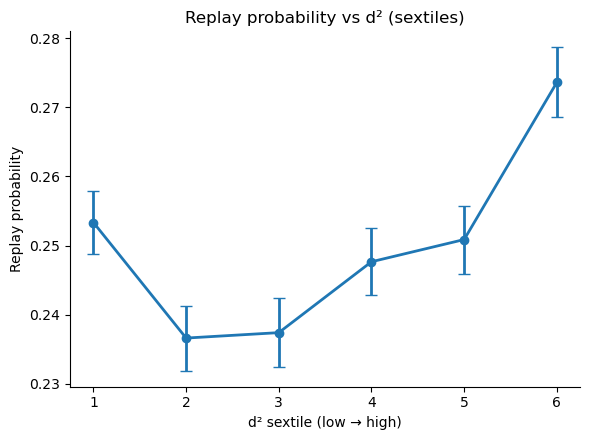

In [38]:
import numpy as np
import pandas as pd

df = ca1_complete_df.copy()
df = df[df["state"].str.upper() == "NREM"].reset_index(drop=True)


# Drop NaNs
df = df.dropna(subset=["d2", "replay_prob"]).copy()

# Sextiles of d2 (1 = lowest, 6 = highest)
df["d2_sextile"] = pd.qcut(
    df["d2"],
    q=6,
    labels=False,
    duplicates="drop"
) + 1

sextile_summary = (
    df
    .groupby("d2_sextile")
    .agg(
        mean_replay_prob=("replay_prob", "mean"),
        sem_replay_prob=("replay_prob", "sem"),
        n_windows=("replay_prob", "size"),
        mean_ripples=("ripple_count", "mean"),
    )
    .reset_index()
)

print(sextile_summary)
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4.5))

ax.errorbar(
    sextile_summary["d2_sextile"],
    sextile_summary["mean_replay_prob"],
    yerr=sextile_summary["sem_replay_prob"],
    fmt="o-",
    linewidth=2,
    capsize=4
)

ax.set_xlabel("d² sextile (low → high)")
ax.set_ylabel("Replay probability")
ax.set_title("Replay probability vs d² (sextiles)")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(False)

plt.tight_layout()
plt.show()


In [40]:
import pickle
save_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\replay\replay_probality"  # <-- your target folder
os.makedirs(save_dir, exist_ok=True)

# build filename and save
fname = f"{animal_name}_{day}.pkl"
save_path = os.path.join(save_dir, fname)

with open(save_path, "wb") as f:
    pickle.dump({"per_center": ca1_complete_df,
                 "animal_name": animal_name,
                 "day": day}, f)

print(f"✅ Saved {save_path}")

✅ Saved D:\Documents\GitHub\Sleep_criticaltiy\data\replay\replay_probality\PPP23_day8.pkl
